# Statistical Analysis — Standalone Notebook

Notebook ini menjalankan **hanya analisis statistik Bayesian** tanpa perlu menjalankan ulang training atau evaluation.

**Yang dibutuhkan:**
- File `complete_evaluation.json` untuk setiap model yang ingin dianalisis (hasil dari `evaluate_pipeline.py` yang sudah pernah dijalankan sebelumnya)
- PyMC ≥ 5.0 dan ArviZ ≥ 0.17

**Urutan sel:**
1. Install dependencies
2. Mount Google Drive (jika di Colab)
3. Set path ke file JSON hasil evaluasi
4. Load dan validasi data
5. Jalankan analisis Bayesian
6. Lihat hasil

## Sel 1 — Install PyMC dan ArviZ

Jalankan sekali. Kalau sudah ter-install, skip saja.

In [1]:
%pip install --no-cache-dir "pymc==6.4.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 619.6/619.6 kB 3.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 7.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 14.7 MB/s  0:00:02
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
  Attempting uninstall: pytensor
    Found existing installation: pytensor 2.38.3
    Uninstalling pytensor-2.38.3:
      Successfully uninstalled pytensor-2.38.3
  Attempting uninstall: arviz
    Found existing installation: arviz 0.22.0
    Uninstalling arviz-0.22.0:
      Successfully uninstalled arviz-0.22.0
  Attempting uninstall: pymc
    Found existing installation: pymc 5.28.5
    Uninstalling pymc-5.28.5:
      Successfully uninstalled pymc-5.28.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pymc]


In [3]:
%cd /content
import zipfile
import os

zip_path = "/content/ths_test.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Rename extracted folder
os.rename(
    "/content/ths_test",
    "/content/domain-shift-trustworthy-ai"
)

/content


## Sel 2 — Mount Google Drive (jika di Colab)

Kalau menjalankan lokal, skip sel ini.

In [2]:
import os

# Deteksi apakah sedang di Google Colab
RUNNING_ON_COLAB = 'COLAB_GPU' in os.environ or os.path.exists('/content')

if RUNNING_ON_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive berhasil di-mount.")
else:
    print("Bukan Colab — skip mount Drive.")

Mounted at /content/drive
Google Drive berhasil di-mount.


## Sel 3 — Tambahkan `src/` ke Python path

Ini agar `import statistical_analyzer` bisa ditemukan.

In [4]:
import sys
import os

# ── Sesuaikan path ini dengan lokasi folder src/ milikmu ──────────────────
# Contoh Colab:
#   SRC_DIR = "/content/drive/MyDrive/thesis/src"
# Contoh lokal Windows:
#   SRC_DIR = r"C:\Users\angel\OneDrive\Dokumen\ANGELA\KULIAH\THESIS WOI\13Jul\ths_test_13Nov\ths_test\src"

SRC_DIR = "/content/domain-shift-trustworthy-ai/src"   # <-- UBAH INI

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

print(f"src/ ditambahkan ke path: {SRC_DIR}")
print(f"Python path: {sys.path[:3]}")

src/ ditambahkan ke path: /content/domain-shift-trustworthy-ai/src
Python path: ['/content/domain-shift-trustworthy-ai/src', '/content', '/env/python']


## Sel 4 — Konfigurasi: path ke file JSON hasil evaluasi

Isi path untuk setiap model yang ingin dianalisis.  
Kalau hanya punya satu model, hapus saja entri yang lain.

In [5]:
import json

# ── UBAH path di bawah ini sesuai lokasi file JSON-mu ─────────────────────
#
# Format:
#   EVAL_JSON_PATHS = {
#       "nama_model": "path/ke/complete_evaluation.json",
#   }
#
# Nama model harus cocok dengan yang ada di dalam file JSON
# (biasanya "base", "large", atau "lite").

EVAL_JSON_PATHS = {
    "base":  "/content/drive/MyDrive/thesis/results/base/complete_evaluation.json",
    "large": "/content/drive/MyDrive/thesis/results/large/complete_evaluation.json",
    "lite":  "/content/drive/MyDrive/thesis/results/lite/complete_evaluation.json",
}

# Folder output untuk menyimpan trace.nc dan report
OUTPUT_DIR = "/content/drive/MyDrive/thesis/statistical_analysis"   # <-- UBAH INI

# ── Validasi: cek file mana yang ada ──────────────────────────────────────
available_paths = {}
for model_name, json_path in EVAL_JSON_PATHS.items():
    if os.path.exists(json_path):
        available_paths[model_name] = json_path
        print(f"  FOUND  {model_name}: {json_path}")
    else:
        print(f"  MISSING {model_name}: {json_path}")

if not available_paths:
    raise FileNotFoundError(
        "Tidak ada file JSON yang ditemukan. "
        "Periksa kembali path di EVAL_JSON_PATHS."
    )

print(f"\n{len(available_paths)} model tersedia untuk analisis: {list(available_paths.keys())}")

  FOUND  base: /content/drive/MyDrive/thesis/results/base/complete_evaluation.json
  FOUND  large: /content/drive/MyDrive/thesis/results/large/complete_evaluation.json
  FOUND  lite: /content/drive/MyDrive/thesis/results/lite/complete_evaluation.json

3 model tersedia untuk analisis: ['base', 'large', 'lite']


## Sel 5 — Load hasil evaluasi dari JSON

`assemble_observations()` di `statistical_analyzer.py` membutuhkan dict dengan format:

```python
{
    "base":  { ...isi complete_evaluation.json untuk base... },
    "large": { ...isi complete_evaluation.json untuk large... },
    "lite":  { ...isi complete_evaluation.json untuk lite... },
}
```

Sel ini membaca setiap file JSON dan merakitnya ke dalam format tersebut.

In [6]:
# Load setiap file JSON dan rakit ke dalam dict all_results
all_results = {}

for model_name, json_path in available_paths.items():
    print(f"Loading {model_name} dari {json_path} ...", end=" ")
    with open(json_path, "r", encoding="utf-8") as f:
        all_results[model_name] = json.load(f)
    print("OK")

print(f"\nLoaded {len(all_results)} model(s): {list(all_results.keys())}")

# Tampilkan top-level keys dari satu model untuk verifikasi struktur
sample_model = list(all_results.keys())[0]
print(f"\nTop-level keys di '{sample_model}': {list(all_results[sample_model].keys())}")

Loading base dari /content/drive/MyDrive/thesis/results/base/complete_evaluation.json ... OK
Loading large dari /content/drive/MyDrive/thesis/results/large/complete_evaluation.json ... OK
Loading lite dari /content/drive/MyDrive/thesis/results/lite/complete_evaluation.json ... OK

Loaded 3 model(s): ['base', 'large', 'lite']

Top-level keys di 'base': ['timestamp', 'domains', 'in_domain', 'cross_domain', 'perturbation', 'cross_domain_perturbation']


## Sel 6 — Validasi observasi (sebelum fitting)

Langkah ini **tidak menjalankan PyMC**. Hanya mengecek kualitas data:
- Berapa banyak observasi yang terkumpul
- Ada NaN atau nilai boundary F1=0/F1=1 tidak
- Ada duplikasi tidak
- Kombinasi eksperimen mana yang hilang

Baca peringatan sebelum lanjut ke fitting.

In [7]:
from statistical_analyzer import assemble_observations, validate_observations
import pandas as pd

# Rakit semua observasi menjadi satu DataFrame flat
print("Merakit observation DataFrame...")
obs_df = assemble_observations(all_results)

print(f"\nJumlah baris: {len(obs_df)}")
print(f"Kolom: {list(obs_df.columns)}")

# Validasi kualitas data
print("\n" + "="*60)
print("VALIDASI DATA")
print("="*60)
val_report = validate_observations(obs_df)

for key, value in val_report.items():
    if key == "warnings":
        continue
    print(f"  {key:<30} : {value}")

print("\nWarnings:")
warnings = val_report.get("warnings", [])
if warnings:
    for w in warnings:
        print(f"  ⚠  {w}")
else:
    print("  Tidak ada warning.")

Merakit observation DataFrame...

Jumlah baris: 300
Kolom: ['model', 'source_domain', 'target_domain', 'perturbation_condition', 'in_domain', 'macro_f1', 'n_samples', 'common_ids_count']

VALIDASI DATA
  n_total                        : 300
  n_out_of_range                 : 0
  n_duplicates                   : 0
  n_scenario_inconsistent        : 0
  n_missing_f1                   : 0
  n_boundary_zero                : 0
  n_boundary_one                 : 2
  f1_min                         : 0.5930851063829787
  f1_max                         : 1.0
  f1_mean                        : 0.8763614523117239
  f1_std                         : 0.06272739229599503
  n_unexpected_categories        : 0
  expected_max                   : 300
  n_models_found                 : 3
  n_missing_combos               : 0
  missing_combinations           : []

Warnings:
  ⚠  2 observation(s) have F1=1.0. Smithson-Verkuilen boundary correction will be applied.


In [8]:
# Tampilkan cuplikan DataFrame untuk verifikasi visual
print("Cuplikan 10 baris pertama:")
display(obs_df.head(10))

print("\nDistribusi per model:")
display(obs_df.groupby("model")["macro_f1"].agg(["count", "mean", "std", "min", "max"]))

print("\nDistribusi per perturbation_condition:")
display(obs_df.groupby("perturbation_condition")["macro_f1"].agg(["count", "mean", "std"]))

print("\nDistribusi in-domain vs cross-domain:")
display(obs_df.groupby("in_domain")["macro_f1"].agg(["count", "mean", "std"]))

Cuplikan 10 baris pertama:


,model,source_domain,target_domain,perturbation_condition,in_domain,macro_f1,n_samples,common_ids_count
0,base,Education,Education,clean,True,0.916190,88,88
1,base,Education,Education,low,True,0.916190,88,88
2,base,Education,Education,medium,True,0.929295,88,88
3,base,Education,Education,high,True,0.914062,88,88
4,base,Health,Health,clean,True,0.903836,77,77
5,base,Health,Health,low,True,0.890780,77,77
6,base,Health,Health,medium,True,0.904989,77,77
7,base,Health,Health,high,True,0.918085,77,77
8,lite,Politics,Politics,clean,True,0.930833,83,83
9,lite,Politics,Politics,low,True,0.930833,83,83



Distribusi per model:


,count,mean,std,min,max
model,,,,,
base,100,0.870283,0.062723,0.708941,1.000000
large,100,0.892608,0.048219,0.752941,0.970283
lite,100,0.866193,0.072222,0.593085,0.957880



Distribusi per perturbation_condition:


,count,mean,std
perturbation_condition,,,
clean,75,0.882635,0.059351
high,75,0.870241,0.065809
low,75,0.874704,0.063092
medium,75,0.877866,0.063099



Distribusi in-domain vs cross-domain:


,count,mean,std
in_domain,,,
False,240,0.863339,0.061582
True,60,0.928453,0.033600


## Sel 7 — Jalankan analisis Bayesian lengkap

**Ini sel yang paling lama** — MCMC sampling bisa memakan waktu 10–30 menit tergantung jumlah draws dan kecepatan CPU/GPU.

Parameter yang bisa disesuaikan:
- `mcmc_draws`: jumlah posterior draws per chain (default: 2000). Kurangi ke 500–1000 untuk testing cepat.
- `mcmc_tune`: jumlah warmup steps (default: 2000). Jangan kurang dari 1000.
- `mcmc_chains`: jumlah chain (default: 4). Minimum 4 untuk R-hat yang reliable.

Hasil disimpan otomatis ke `OUTPUT_DIR` sebagai:
- `trace.nc` — posterior trace (bisa di-load ulang tanpa fitting ulang)
- `statistical_analysis.json` — semua hasil dalam format JSON
- `statistical_analysis_report.txt` — laporan teks yang bisa dibaca manusia

In [9]:
# %pip uninstall -y pymc arviz pytensor

# %pip install --no-cache-dir --upgrade \
#     pymc \
#     arviz \
#     pytensor

In [10]:
import sys
import pymc as pm
import arviz as az
import pytensor

print("Python :", sys.version)
print("PyMC   :", pm.__version__)
print("ArviZ  :", az.__version__)
print("PyTensor:", pytensor.__version__)

print("ArviZ stats available:", hasattr(az, "stats"))

Python : 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyMC   : 6.4.0
ArviZ  : 1.3.0
PyTensor: 3.3.8
ArviZ stats available: False


In [11]:
from statistical_analyzer import StatisticalAnalyzer

# ── Konfigurasi MCMC & Pilihan Pair Effect ─────────────────────────────────
# Pair Mode Specification:
#   'A' : 0 pair effects (no pair random effect)
#   'B' : 25 pair effects (all source-target pairs)
#   'C' : 20 pair effects (off-diagonal cross-domain only, default & recommended)
#
# Untuk testing cepat (smoke test):
#   mcmc_draws=100, mcmc_tune=100, mcmc_chains=2
# Untuk laporan akhir thesis:
#   mcmc_draws=2000, mcmc_tune=2000, mcmc_chains=4

analyzer = StatisticalAnalyzer(
    random_seed  = 42,
    output_dir   = OUTPUT_DIR,
    mcmc_draws   = 2000,
    mcmc_tune    = 2000,
    mcmc_chains  = 4,
    pair_mode    = "C",   # <-- Ganti 'A', 'B', atau 'C'
)

print("Memulai analisis Bayesian...")
print(f"Output akan disimpan di: {OUTPUT_DIR}")
print("-" * 60)

results = analyzer.run_full_analysis(all_results)

print("-" * 60)
print(f"Status: {results['status']}")
if results['status'] == 'completed':
    print(f"Report disimpan di: {results.get('report_path', '?')}")


Memulai analisis Bayesian...
Output akan disimpan di: /content/drive/MyDrive/thesis/statistical_analysis
------------------------------------------------------------


Output()

Output()

BAYESIAN STATISTICAL ANALYSIS REPORT
IndoBERT Clickbait Robustness Study

Status : completed_with_warnings
Detail : {'sampling_converged': True, 'ppc_structurally_valid': True, 'ppc_fit_ok': False, 'contrasts_valid': True, 'design_complete_300': True}
  ('completed' = sampling converged AND PPC fit acceptable AND full 300-cell design.
   Structural PPC validation alone does NOT mean the model fits the data.)

OBSERVATION SUMMARY
----------------------------------------
  Total observations   : 300
  Missing F1           : 0
  Boundary F1=0        : 0
  Boundary F1=1        : 2
  F1 range             : [0.5931, 1.0000]
  F1 mean (std)        : 0.8764 (0.0627)
  Missing combinations : 0


CONVERGENCE DIAGNOSTICS
----------------------------------------
  R-hat max            : 1.0014
  Bulk-ESS min         : 2490
  Tail-ESS min         : 3715
  Divergences          : 0
  Converged            : True
  (R-hat near 1.0, ESS > ~400, 0 divergences = good)


POSTERIOR PREDICTIVE CHECK
--------

## Sel 8 — Lihat hasil: Konvergensi MCMC

In [12]:
conv = results.get("convergence", {})

if not conv:
    print("Tidak ada hasil konvergensi (mungkin fitting gagal).")
else:
    print("MCMC CONVERGENCE DIAGNOSTICS")
    print("=" * 40)
    print(f"  R-hat max     : {conv.get('rhat_max', float('nan')):.4f}"
          + (" ✓ OK" if conv.get('rhat_max', 99) <= 1.01 else " ⚠ WARNING"))
    print(f"  Bulk-ESS min  : {conv.get('ess_bulk_min', float('nan')):.0f}"
          + (" ✓ OK" if conv.get('ess_bulk_min', 0) >= 400 else " ⚠ WARNING"))
    print(f"  Tail-ESS min  : {conv.get('ess_tail_min', float('nan')):.0f}"
          + (" ✓ OK" if conv.get('ess_tail_min', 0) >= 400 else " ⚠ WARNING"))
    print(f"  Divergences   : {conv.get('n_divergences', '?')}"
          + (" ✓ OK" if conv.get('n_divergences', 1) == 0 else " ⚠ WARNING"))


    if conv.get("warnings"):
        print("\nWarnings:")
        for w in conv["warnings"]:
            print(f"  ⚠ {w}")

MCMC CONVERGENCE DIAGNOSTICS
  R-hat max     : 1.0014 ✓ OK
  Bulk-ESS min  : 2490 ✓ OK
  Tail-ESS min  : 3715 ✓ OK
  Divergences   : 0 ✓ OK


## Sel 9 — Lihat hasil: Posterior Predictive Check (PPC)

In [13]:
import pandas as pd

ppc = results.get("ppc", {})

if not ppc:
    print("Tidak ada hasil PPC.")
else:
    # Pooled statistics
    obs_s   = ppc["observed"]
    pred_s  = ppc["predicted"]
    bayes_p = ppc["bayesian_p_values"]

    print("POSTERIOR PREDICTIVE CHECK — Pooled")
    print("=" * 55)
    print(f"{'Statistic':<10}  {'Observed':>9}  {'Predicted':>9}  {'Bayes-p':>9}")
    print("-" * 42)
    for stat in ["mean", "std", "min", "max", "q10", "q90"]:
        o = obs_s.get(stat, float('nan'))
        p = pred_s.get(stat, float('nan'))
        b = bayes_p.get(stat, float('nan'))
        print(f"{stat:<10}  {o:>9.4f}  {p:>9.4f}  {b:>9.3f}")

    # Per-condition grouped check
    gc = ppc.get("grouped_mean_by_condition", {})
    if gc:
        print("\nPPC — Per Perturbation Condition")
        print("-" * 55)
        print(f"{'Condition':<10}  {'Obs mean':>9}  {'Pred mean':>9}  {'Bayes-p':>9}  {'N':>5}")
        for cond in ["clean", "low", "medium", "high"]:
            if cond in gc:
                v = gc[cond]
                print(f"{cond:<10}  {v['obs_mean']:>9.4f}  "
                      f"{v['pred_mean']:>9.4f}  {v['bayesian_p']:>9.3f}  {v['n_obs']:>5}")

    # Per-scenario grouped check
    gs = ppc.get("grouped_mean_by_scenario", {})
    if gs:
        print("\nPPC — Per Scenario")
        print("-" * 55)
        print(f"{'Scenario':<14}  {'Obs mean':>9}  {'Pred mean':>9}  {'Bayes-p':>9}  {'N':>5}")
        for scen in ["in_domain", "cross_domain"]:
            if scen in gs:
                v = gs[scen]
                print(f"{scen:<14}  {v['obs_mean']:>9.4f}  "
                      f"{v['pred_mean']:>9.4f}  {v['bayesian_p']:>9.3f}  {v['n_obs']:>5}")

    print(f"\nNote: {ppc.get('note', '')}")

POSTERIOR PREDICTIVE CHECK — Pooled
Statistic    Observed  Predicted    Bayes-p
------------------------------------------
mean           0.8751     0.8749      0.471
std            0.0624     0.0636      0.661
min            0.5928     0.6454      0.940
max            0.9983     0.9881      0.003
q10            0.8049     0.7883      0.008
q90            0.9417     0.9486      0.978

PPC — Per Perturbation Condition
-------------------------------------------------------
Condition    Obs mean  Pred mean    Bayes-p      N
clean          0.8814     0.8813      0.504     75
low            0.8735     0.8725      0.433     75
medium         0.8766     0.8770      0.531     75
high           0.8690     0.8688      0.486     75

PPC — Per Scenario
-------------------------------------------------------
Scenario         Obs mean  Pred mean    Bayes-p      N
in_domain          0.9270     0.9279      0.576     60
cross_domain       0.8621     0.8617      0.443    240

Note: All statistics use b

## Sel 10 — Lihat hasil: Posterior Contrasts (semua RQ)

In [14]:
import pandas as pd

contrasts = results.get("contrasts", {})

if not contrasts or "error" in contrasts:
    print("Tidak ada hasil contrasts:", contrasts.get("error", "unknown"))
else:
    # Konversi ke DataFrame untuk tampilan yang lebih rapi
    rows = []
    for name, c in contrasts.items():
        rows.append({
            "contrast":      name,
            "mean":          c["mean"],
            "ci_lower":      c["ci_95_lower"],
            "ci_upper":      c["ci_95_upper"],
            "P(positive)": c["prob_positive"],
            "P(negative)": c["prob_negative"],
        })
    df_contrasts = pd.DataFrame(rows)

    # ── RQ1: Model variant comparisons ─────────────────────────────────────
    rq1 = df_contrasts[df_contrasts["contrast"].str.startswith("model_")]
    if not rq1.empty:
        print("\nRQ1 — Model Variant Comparisons")
        print("Positive = model pertama punya F1 lebih tinggi dari model kedua")
        display(rq1.set_index("contrast").round(4))

    # ── RQ2: In-domain vs cross-domain ──────────────────────────────────────
    rq2 = df_contrasts[df_contrasts["contrast"] == "in_domain_vs_cross_domain"]
    if not rq2.empty:
        print("\nRQ2 — In-Domain vs Cross-Domain")
        print("Positive = in-domain punya F1 lebih tinggi dari cross-domain")
        display(rq2.set_index("contrast").round(4))

    # ── RQ3: Perturbation degradation ───────────────────────────────────────
    rq3_keys = [k for k in contrasts if k.startswith("clean_vs_") or k in ("low_vs_medium", "medium_vs_high")]
    rq3 = df_contrasts[df_contrasts["contrast"].isin(rq3_keys)]
    if not rq3.empty:
        print("\nRQ3 — Perturbation Degradation")
        print("Positive = F1 turun dari kondisi pertama ke kondisi kedua (degradasi)")
        display(rq3.set_index("contrast").round(4))

    # ── RQ4: Model × Perturbation interaction ───────────────────────────────
    rq4 = df_contrasts[df_contrasts["contrast"].str.startswith("interaction_degradation_")]
    if not rq4.empty:
        print("\nRQ4 — Model × Perturbation Interaction")
        print("Positive = model pertama degradasi LEBIH dari model kedua di level tersebut")
        display(rq4.set_index("contrast").round(4))

    # ── RQ5: Perturbation × Scenario interaction ────────────────────────────
    rq5 = df_contrasts[df_contrasts["contrast"].str.startswith("interaction_scenario_")]
    if not rq5.empty:
        print("\nRQ5 — Perturbation × Scenario Interaction")
        print("Negative = cross-domain degradasi LEBIH dari in-domain (arah yang diharapkan)")
        display(rq5.set_index("contrast").round(4))


RQ1 — Model Variant Comparisons
Positive = model pertama punya F1 lebih tinggi dari model kedua


,mean,ci_lower,ci_upper,P(positive),P(negative)
contrast,,,,,
model_base_vs_large,-0.0207,-0.0293,-0.0120,0.0000,1.0000
model_base_vs_lite,0.0050,-0.0041,0.0142,0.8646,0.1354
model_large_vs_lite,0.0257,0.0169,0.0344,1.0000,0.0000



RQ2 — In-Domain vs Cross-Domain
Positive = in-domain punya F1 lebih tinggi dari cross-domain


,mean,ci_lower,ci_upper,P(positive),P(negative)
contrast,,,,,
in_domain_vs_cross_domain,0.0662,0.0586,0.0736,1.0,0.0



RQ3 — Perturbation Degradation
Positive = F1 turun dari kondisi pertama ke kondisi kedua (degradasi)


,mean,ci_lower,ci_upper,P(positive),P(negative)
contrast,,,,,
clean_vs_low,0.0089,-0.0013,0.0190,0.9564,0.0436
clean_vs_medium,0.0044,-0.0055,0.0143,0.8020,0.1980
clean_vs_high,0.0127,0.0024,0.0230,0.9908,0.0092
low_vs_medium,-0.0045,-0.0143,0.0055,0.1918,0.8082
medium_vs_high,0.0083,-0.0018,0.0185,0.9485,0.0515



RQ4 — Model × Perturbation Interaction
Positive = model pertama degradasi LEBIH dari model kedua di level tersebut


,mean,ci_lower,ci_upper,P(positive),P(negative)
contrast,,,,,
interaction_degradation_base_vs_large_at_low,-0.0094,-0.0329,0.0146,0.2142,0.7857
interaction_degradation_base_vs_large_at_medium,-0.0158,-0.0401,0.0081,0.0995,0.9005
interaction_degradation_base_vs_large_at_high,-0.0069,-0.0309,0.0173,0.2905,0.7095
interaction_degradation_base_vs_lite_at_low,0.0031,-0.0219,0.0277,0.5981,0.4019
interaction_degradation_base_vs_lite_at_medium,-0.0065,-0.0311,0.0185,0.3018,0.6982
interaction_degradation_base_vs_lite_at_high,-0.0030,-0.0287,0.0217,0.4049,0.5951
interaction_degradation_large_vs_lite_at_low,0.0124,-0.0117,0.0370,0.8498,0.1502
interaction_degradation_large_vs_lite_at_medium,0.0092,-0.0148,0.0338,0.7738,0.2262
interaction_degradation_large_vs_lite_at_high,0.0039,-0.0201,0.0279,0.6195,0.3805



RQ5 — Perturbation × Scenario Interaction
Negative = cross-domain degradasi LEBIH dari in-domain (arah yang diharapkan)


,mean,ci_lower,ci_upper,P(positive),P(negative)
contrast,,,,,
interaction_scenario_degradation_at_low,0.0037,-0.0175,0.0242,0.6399,0.3601
interaction_scenario_degradation_at_medium,-0.0073,-0.0272,0.0123,0.2376,0.7624
interaction_scenario_degradation_at_high,0.0015,-0.0187,0.0219,0.5580,0.4420


## Sel 11 — Baca laporan teks lengkap

In [15]:
report_path = results.get("report_path", "")

if report_path and os.path.exists(report_path):
    with open(report_path, "r", encoding="utf-8") as f:
        print(f.read())
else:
    print(f"File laporan tidak ditemukan: {report_path}")

BAYESIAN STATISTICAL ANALYSIS REPORT
IndoBERT Clickbait Robustness Study

Status : completed_with_warnings
Detail : {'sampling_converged': True, 'ppc_structurally_valid': True, 'ppc_fit_ok': False, 'contrasts_valid': True, 'design_complete_300': True}
  ('completed' = sampling converged AND PPC fit acceptable AND full 300-cell design.
   Structural PPC validation alone does NOT mean the model fits the data.)

OBSERVATION SUMMARY
----------------------------------------
  Total observations   : 300
  Missing F1           : 0
  Boundary F1=0        : 0
  Boundary F1=1        : 2
  F1 range             : [0.5931, 1.0000]
  F1 mean (std)        : 0.8764 (0.0627)
  Missing combinations : 0


CONVERGENCE DIAGNOSTICS
----------------------------------------
  R-hat max            : 1.0014
  Bulk-ESS min         : 2490
  Tail-ESS min         : 3715
  Divergences          : 0
  Converged            : True
  (R-hat near 1.0, ESS > ~400, 0 divergences = good)


POSTERIOR PREDICTIVE CHECK
--------

---
# **AUDIT**

---

In [57]:
%cd /content/domain-shift-trustworthy-ai

!python audit/02_make_hybrid_300.py

/content/domain-shift-trustworthy-ai

Processing BASE...

Processing LARGE...

Processing LITE...

REAL DATASET SUMMARY
Output: /tmp/audit/hybrid_300.csv
Shape: (300, 8)

Rows per model:
model
base     100
large    100
lite     100
dtype: int64

Matched sample sizes:
target_domain  Education  Health  Politics  Sport  Technology
model                                                        
base                  88      77        83     51          62
large                 88      77        83     51          62
lite                  88      77        83     51          62

Macro-F1 summary:
       count      mean       std       min       max
model                                               
base     100  0.870283  0.062723  0.708941  1.000000
large    100  0.892608  0.048219  0.752941  0.970283
lite     100  0.866193  0.072222  0.593085  0.957880

F1 == 1:
model
base     2
large    0
lite     0
Name: f1_is_one, dtype: int64

Diagonal consistency:
       sum  count
model            


In [58]:
%cd /content/domain-shift-trustworthy-ai

!python audit/06_experiments.py

/content/domain-shift-trustworthy-ai
A_current(sv300,shared_phi,no_pair) done in 59 s | div 0 | rhat 1.004 | n_out 13 | pairT p 0.0
B_pair_w25_shared done in 89 s | div 0 | rhat 1.004 | n_out 8 | pairT p 0.45
C_pair_w20_offdiag done in 83 s | div 0 | rhat 1.003 | n_out 8 | pairT p 0.446
There were 22 divergences after tuning. Increase `target_accept` or reparameterize.
D_pair_w75 done in 156 s | div 22 | rhat 1.004 | n_out 3 | pairT p 0.482
E_ymode_sv_ni_boundary done in 58 s | div 0 | rhat 1.004 | n_out 13 | pairT p 0.001
F_ymode_clip_boundary done in 52 s | div 0 | rhat 1.004 | n_out 13 | pairT p 0.001
G_phi_by_target done in 70 s | div 0 | rhat 1.004 | n_out 10 | pairT p 0.011
H_pair_w20+clip done in 78 s | div 0 | rhat 1.005 | n_out 11 | pairT p 0.449
ALL DONE


In [63]:
for name, r in results.items():
    print("\n", name)
    print("Keys:", list(r.keys()))

    if "pair_T" in r:
        print("pair_T:", r["pair_T"])


 A_current(sv300,shared_phi,no_pair)
Keys: ['tag', 'secs', 'rhat_max', 'ess_min', 'div', 'lam', 'phi', 'sigma_u', 'sigma_w', 'ppc_min', 'ppc_max', 'ppc_std', 'n_out', 'pair_T', 'in_vs_cross', 'base_minus_large', 'large_minus_lite', 'base_minus_lite', 'clean_vs_high', 'clean_vs_low', 'loo']
pair_T: {'obs_mean': 0.01650288276480699, 'rep_mean': 0.010069649858402849, 'p_rep_ge_obs': 0.00025}

 B_pair_w25_shared
Keys: ['tag', 'secs', 'rhat_max', 'ess_min', 'div', 'lam', 'phi', 'sigma_u', 'sigma_w', 'ppc_min', 'ppc_max', 'ppc_std', 'n_out', 'pair_T', 'in_vs_cross', 'base_minus_large', 'large_minus_lite', 'base_minus_lite', 'clean_vs_high', 'clean_vs_low', 'loo']
pair_T: {'obs_mean': 0.009389715433190879, 'rep_mean': 0.009136189595931191, 'p_rep_ge_obs': 0.4495}

 C_pair_w20_offdiag
Keys: ['tag', 'secs', 'rhat_max', 'ess_min', 'div', 'lam', 'phi', 'sigma_u', 'sigma_w', 'ppc_min', 'ppc_max', 'ppc_std', 'n_out', 'pair_T', 'in_vs_cross', 'base_minus_large', 'large_minus_lite', 'base_minus_lite

In [64]:
import json
import pandas as pd

with open("/tmp/audit/experiments.json") as f:
    results = json.load(f)

contrast_names = [
    "in_vs_cross",
    "base_minus_large",
    "large_minus_lite",
    "base_minus_lite",
    "clean_vs_high",
    "clean_vs_low",
]

rows = []

for exp, result in results.items():
    for contrast in contrast_names:
        value = result.get(contrast)

        if isinstance(value, dict):
            rows.append({
                "experiment": exp,
                "contrast": contrast,
                **value
            })
        else:
            rows.append({
                "experiment": exp,
                "contrast": contrast,
                "value": value
            })

df_contrasts = pd.DataFrame(rows)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

display(df_contrasts)

,experiment,contrast,mean,lo,hi,p_pos
0,"A_current(sv300,shared_phi,no_pair)",in_vs_cross,0.066200,0.058107,0.074014,1.00000
1,"A_current(sv300,shared_phi,no_pair)",base_minus_large,-0.019502,-0.028726,-0.010126,0.00000
2,"A_current(sv300,shared_phi,no_pair)",large_minus_lite,0.025326,0.016044,0.034757,1.00000
3,"A_current(sv300,shared_phi,no_pair)",base_minus_lite,0.005825,-0.003673,0.015578,0.88075
4,"A_current(sv300,shared_phi,no_pair)",clean_vs_high,0.012790,0.001705,0.023955,0.98875
5,"A_current(sv300,shared_phi,no_pair)",clean_vs_low,0.008959,-0.001511,0.019668,0.95050
6,B_pair_w25_shared,in_vs_cross,0.066046,0.058327,0.073640,1.00000
7,B_pair_w25_shared,base_minus_large,-0.020845,-0.029258,-0.012285,0.00000
8,B_pair_w25_shared,large_minus_lite,0.025694,0.016744,0.034489,1.00000
9,B_pair_w25_shared,base_minus_lite,0.004849,-0.004176,0.013746,0.86025


---
---

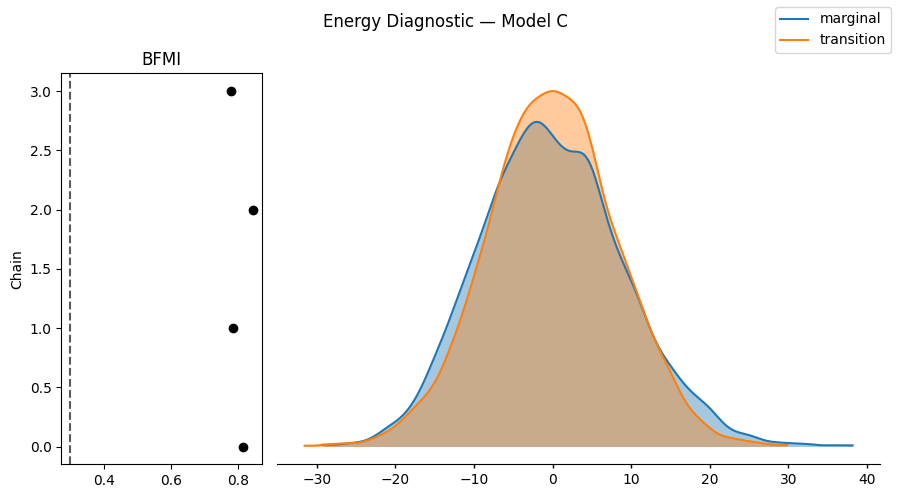

In [84]:

import matplotlib.pyplot as plt
import arviz as az

plot_vars = [
    "alpha", "lambda", "phi",
    "sigma_u", "sigma_w",
    "beta_m", "gamma_s", "delta_t",
    "zeta_p", "xi_p"
]

# Removed compact=True to prevent ValueError with ArviZ 1.3.0+ (arviz_plots backend)
fig = az.plot_trace(
    idata,
    var_names=plot_vars
)
plt.gcf().suptitle("Trace Plot — Model C", y=1.02)
plt.gcf().set_size_inches(14, 18)
plt.tight_layout()
plt.show()

fig = az.plot_energy(idata)
plt.gcf().suptitle("Energy Diagnostic — Model C")
plt.gcf().set_size_inches(9, 5)
plt.tight_layout()
plt.show()

from IPython.display import display
display(plt.gcf())

In [79]:

w = idata.posterior["w_st"]

print("w_st dimensions:", w.dims)
print("w_st shape:", w.shape)

# Rata-rata posterior per pasangan source-target
w_mean = w.mean(dim=("chain", "draw")).values

print("\nPosterior mean w_st:")
print(np.round(w_mean, 5))

print("\nDiagonal:")
print(np.round(np.diag(w_mean), 8))

print("\nDiagonal maximum absolute value:")
print(np.max(np.abs(np.diag(w_mean))))

print("\nOff-diagonal mean absolute value:")
mask = ~np.eye(5, dtype=bool)
print(np.mean(np.abs(w_mean[mask])))


w_st dimensions: ('chain', 'draw', 'w_st_dim_0', 'w_st_dim_1')
w_st shape: (4, 2000, 5, 5)

Posterior mean w_st:
[[ 0.       0.16904 -0.06383 -0.05096 -0.02273]
 [ 0.03491  0.       0.16651  0.08865  0.01678]
 [-0.11127 -0.2779   0.      -0.17178  0.02255]
 [-0.03616  0.24234 -0.06822  0.       0.03184]
 [ 0.11974  0.13385 -0.43225  0.18289  0.     ]]

Diagonal:
[0. 0. 0. 0. 0.]

Diagonal maximum absolute value:
0.0

Off-diagonal mean absolute value:
0.12220965977350837


---
---

## Sel 12 — (Opsional) Load trace yang sudah ada tanpa fitting ulang

Kalau `trace.nc` sudah ada dari sesi sebelumnya dan kamu hanya ingin melihat ulang hasilnya tanpa fitting ulang.

In [ ]:
# ── Opsional: load trace dari file ────────────────────────────────────────
# Jalankan sel ini HANYA kalau ingin load trace yang sudah ada,
# BUKAN setelah baru saja menjalankan Sel 7.

import arviz as az
from statistical_analyzer import (
    assemble_observations, run_convergence_diagnostics,
    run_posterior_predictive_check, compute_contrasts, apply_boundary_correction
)
import numpy as np

trace_path = os.path.join(OUTPUT_DIR, "trace.nc")

if not os.path.exists(trace_path):
    print(f"File trace tidak ditemukan: {trace_path}")
    print("Jalankan fitting terlebih dahulu.")
else:
    print(f"Loading trace dari {trace_path} ...")
    loaded_trace = az.from_netcdf(trace_path)

    # Rakit obs_df ulang
    obs_df_reload = assemble_observations(all_results).dropna(subset=["macro_f1"]).copy()
    y_raw = obs_df_reload["macro_f1"].values.astype(float)
    if np.any(y_raw <= 0.0) or np.any(y_raw >= 1.0):
        obs_df_reload["macro_f1_corrected"] = apply_boundary_correction(y_raw, n=len(y_raw))
    else:
        obs_df_reload["macro_f1_corrected"] = y_raw.copy()

    # Encodings
    encodings = {
        "models": sorted(obs_df_reload["model"].unique().tolist()),
        "sources": sorted(obs_df_reload["source_domain"].unique().tolist()),
        "targets": sorted(obs_df_reload["target_domain"].unique().tolist()),
        "conditions": ["clean", "low", "medium", "high"],
        "pair_effect": "w_st" in loaded_trace.posterior,
    }

    conv_reload = run_convergence_diagnostics(loaded_trace)
    ppc_reload = run_posterior_predictive_check(loaded_trace, obs_df_reload)
    contrasts_reload = compute_contrasts(loaded_trace, encodings, obs_df_reload)
    print(f"\nR-hat max: {conv_reload['rhat_max']:.4f}")
    print(f"Divergences: {conv_reload['n_divergences']}")
    print(f"Total contrasts computed: {len(contrasts_reload)}")

In [ ]:
# ── Opsional: load trace dari file ────────────────────────────────────────
# Jalankan sel ini HANYA kalau ingin load trace yang sudah ada,
# BUKAN setelah baru saja menjalankan Sel 7.

import os
import arviz as az
from statistical_analyzer import StatisticalAnalyzer, assemble_observations

trace_path = os.path.join(OUTPUT_DIR, "trace.nc")

if not os.path.exists(trace_path):
    print(f"File trace tidak ditemukan: {trace_path}")
    print("Jalankan Sel 7 terlebih dahulu untuk melakukan fitting.")
else:
    print(f"Loading trace dari {trace_path} ...")
    loaded_trace = az.from_netcdf(trace_path)

    # Inisialisasi analyzer
    analyzer = StatisticalAnalyzer(
        random_seed = 42,
        output_dir  = OUTPUT_DIR,
    )

    # Rakit kembali DataFrame observasi
    obs_df_reload = assemble_observations(all_results)
    analyzer.obs_df = obs_df_reload

    # Masukkan trace hasil load ke dalam model wrapper di dalam analyzer
    analyzer.model.trace = loaded_trace

    # Rebuild encodings
    models     = sorted(obs_df_reload["model"].unique().tolist())
    sources    = sorted(obs_df_reload["source_domain"].unique().tolist())
    targets    = sorted(obs_df_reload["target_domain"].unique().tolist())
    conditions = ["clean", "low", "medium", "high"]

    analyzer.model._encodings = {
        "models": models, "sources": sources,
        "targets": targets, "conditions": conditions,
    }

    # Hitung boundary correction jika diperlukan
    from statistical_analyzer import apply_boundary_correction
    import numpy as np
    y_raw = obs_df_reload["macro_f1"].values.astype(float)
    if np.any(y_raw <= 0.0) or np.any(y_raw >= 1.0):
        analyzer.model.obs_df = obs_df_reload.copy()
        analyzer.model.obs_df["macro_f1_corrected"] = apply_boundary_correction(y_raw, n=len(y_raw))
    else:
        analyzer.model.obs_df = obs_df_reload.copy()
        analyzer.model.obs_df["macro_f1_corrected"] = y_raw.copy()

    print("Trace berhasil di-load ke analyzer.")
    print("\nSekarang kamu bisa memanggil:")
    print("  analyzer.model.convergence_diagnostics()")
    print("  analyzer.model.posterior_predictive_check()")
    print("  analyzer.model.compute_contrasts()")

    # Tampilkan konvergensi langsung untuk verifikasi
    conv_reload = analyzer.model.convergence_diagnostics()
    print(f"\nR-hat max: {conv_reload['rhat_max']:.4f}")
    print(f"Divergences: {conv_reload['n_divergences']}")

Loading trace dari /content/drive/MyDrive/thesis/statistical_analysis/trace.nc ...


AttributeError: 'StatisticalAnalyzer' object has no attribute 'model'

## Sel 13 — (Opsional) Jalankan test suite

Memverifikasi bahwa logika filtering RQ2/RQ5, penanganan duplikat, dan perhitungan PPC bekerja dengan benar. Tidak membutuhkan PyMC.

In [ ]:
from statistical_analyzer import run_all_tests
run_all_tests()

ERROR:statistical_analyzer:  CONFLICT key=('base', 'DomA', 'DomA', 'clean')  sources=['perturbation', 'cross_domain_perturbation']  F1 values=['0.900000', '0.800000']


Running statistical_analyzer tests ...
  PASSED: test_rq2_in_domain_filter
  PASSED: test_rq5_scenario_uses_correct_cells
  PASSED: test_summarise_contrast_values
  PASSED: test_duplicate_handling_in_assemble
  PASSED: test_conflicting_duplicates_raise
  PASSED: test_ppc_statistics_shape_and_scale
  PASSED: test_validate_observations_flags_issues
  PASSED: test_boundary_correction

All 8 tests passed.
